In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

warnings.filterwarnings("ignore")
%config InlineBackend.figure_formats = ["retina"]
plt.rcParams.update({
    "figure.figsize": (9, 4.2),
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
                                         "#4a3aa7", "#e34948"]),
    "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", 14)
pd.set_option("display.width", 120)

# Informalidad por departamento

`dane-data` replica la medición de informalidad del DANE (17.ª CIET): los asalariados son formales si
cotizan a salud y a pensión por su trabajo; los cuenta propia y patrones, si su negocio tiene registro
mercantil o contabilidad (vea {doc}`../guia/variables`). Los informales de cada mes coinciden con los que
publica el DANE. La medición existe desde 2022.

In [2]:
import dane_data as dd

dpto = dd.geih.serie_indicadores(2025, por="departamento")
dpto[["departamento", "ocupados", "tasa_informalidad", "n_muestra"]].sort_values("tasa_informalidad").round(1)

,departamento,ocupados,tasa_informalidad,n_muestra
26,San Andrés,20982.9,24.1,8340
4,Bogotá D.C.,4322854.5,35.5,26316
23,Putumayo,17166.2,35.7,4347
31,Vaupés,5321.8,36.1,5235
13,Cundinamarca,1740859.3,42.6,16190
1,Antioquia,3383382.5,48.0,47177
25,Risaralda,463756.1,49.1,36638
9,Casanare,81569.7,49.8,5223
24,Quindío,262495.1,50.1,31530
7,Caldas,481833.3,50.4,38633


Cada departamento tiene una muestra distinta; las cifras de los departamentos con pocas observaciones
(`n_muestra`) tienen más error de muestreo.

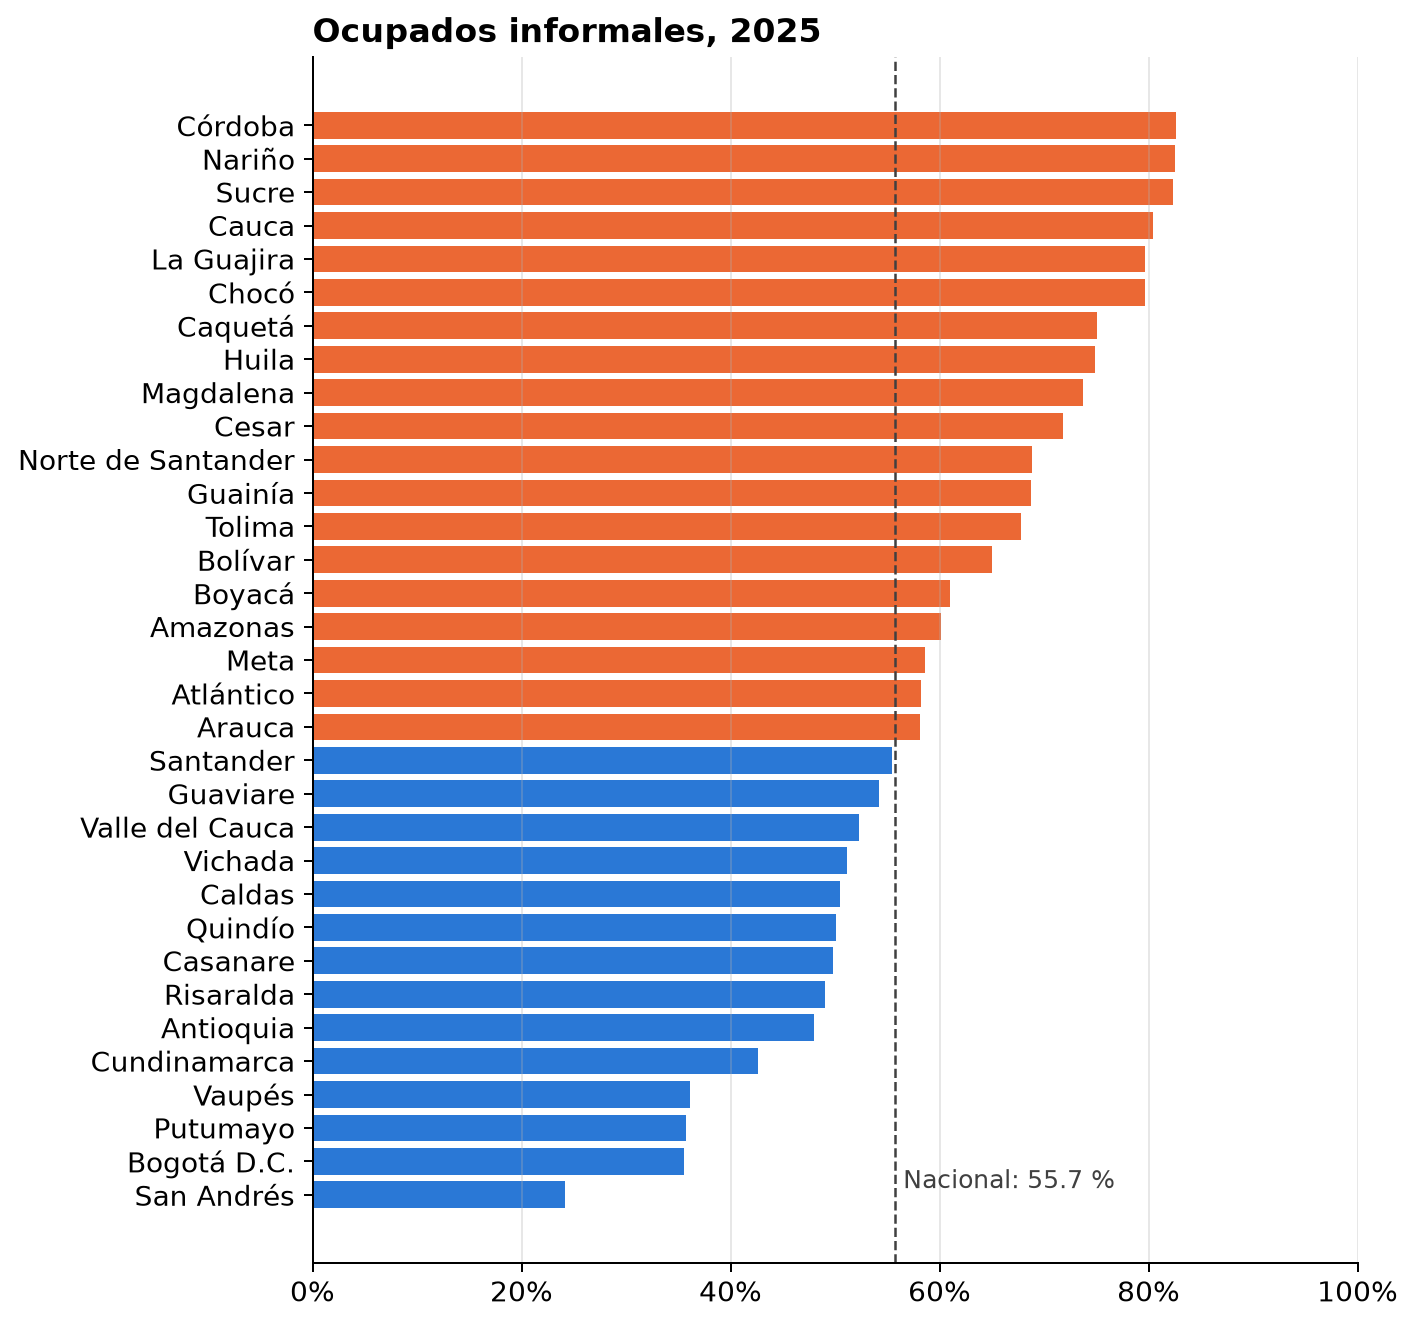

In [3]:
d = dpto.dropna(subset=["departamento"]).sort_values("tasa_informalidad")
nacional = dd.geih.serie_indicadores(2025)["tasa_informalidad"].iloc[0]

fig, ax = plt.subplots(figsize=(8, 7.5))
colores = ["#eb6834" if t > nacional else "#2a78d6" for t in d["tasa_informalidad"]]
ax.barh(d["departamento"].astype(str), d["tasa_informalidad"], color=colores)
ax.axvline(nacional, color="0.25", lw=1, ls="--")
ax.text(nacional + 0.8, 0.2, f"Nacional: {nacional:.1f} %", fontsize=10, color="0.25")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(0, 100)
ax.set_title("Ocupados informales, 2025")
ax.grid(axis="y", visible=False)
fig.tight_layout();

## Por zona y nivel educativo

In [4]:
zona = dd.geih.serie_indicadores(2025, por="zona")[["zona", "tasa_informalidad"]]
educ = dd.geih.serie_indicadores(2025, por="nivel_educativo")[["nivel_educativo", "tasa_informalidad"]]
zona.round(1), educ.dropna().round(1)

(                                  zona  tasa_informalidad
 0                    Urbano (cabecera)               48.6
 1  Rural (centros poblados y disperso)               83.5,
   nivel_educativo  tasa_informalidad
 0         Ninguno               95.1
 1        Primaria               84.3
 2      Secundaria               79.5
 3           Media               57.8
 4        Superior               26.8)

La informalidad es mucho mayor en la zona rural y baja con la educación: entre quienes tienen educación
superior es una fracción de la de quienes solo tienen primaria.

## En el tiempo

In [5]:
serie = dd.geih.serie_indicadores(range(2022, 2026), por="zona")
serie.pivot(index="anio", columns="zona", values="tasa_informalidad").round(1)

zona,Urbano (cabecera),Rural (centros poblados y disperso)
anio,,
2022,50.8,84.6
2023,49.1,84.0
2024,48.6,83.9
2025,48.6,83.5
